In [1]:
from dotenv import load_dotenv
load_dotenv(override=True)  # reads .env into os.enviro

True

In [2]:
import os, getpass

def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("OPENAI_API_KEY")

In [3]:
_set_env("LANGSMITH_API_KEY")
_set_env("LANGSMITH_TRACING")
_set_env("LANGSMITH_PROJECT")

In [5]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage
messages = [AIMessage(f"So you said you were researching ocean mammals?", name="Bot")]
messages.append(HumanMessage(f"Yes, I know about whales. But what others should I learn about?", name="Ian"))

for m in messages:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Ian

Yes, I know about whales. But what others should I learn about?


In [6]:
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model="gpt-4o")
llm.invoke(messages)

AIMessage(content='Aside from whales, there are several fascinating ocean mammals that you might want to learn about:\n\n1. **Dolphins** - Closely related to whales and porpoises, dolphins are known for their intelligence, sociable nature, and playful behavior. They are found in warm and temperate seas worldwide.\n\n2. **Porpoises** - Similar to dolphins but generally smaller and stouter, porpoises are shy creatures that live in coastal waters. They have a unique jaw and teeth structure compared to dolphins.\n\n3. **Seals** - Part of the pinniped family, seals are divided into true seals, eared seals (including sea lions and fur seals), and walruses. They are known for their adaptability both in water and on land.\n\n4. **Sea Lions** - These are eared seals known for their external ear flaps and ability to "walk" on land using their flippers. They are social animals often seen in groups.\n\n5. **Walruses** - Large mammals with distinctive tusks and whiskers, walruses are found in Arcti

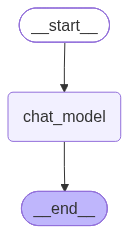

In [7]:
from IPython.display import Image, display
from langgraph.graph import MessagesState
from langgraph.graph import StateGraph, START, END

# Node
def chat_model_node(state: MessagesState):
    return {"messages": llm.invoke(state["messages"])}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [8]:
output = graph.invoke({'messages': messages})
for m in output['messages']:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Ian

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

In addition to whales, there are several fascinating ocean mammals you can explore:

1. **Dolphins**: Known for their intelligence and social behavior, dolphins are found in oceans worldwide. Species to look into include the bottlenose dolphin, the common dolphin, and the orca (or killer whale, which is actually a type of dolphin).

2. **Porpoises**: Similar to dolphins but generally smaller with distinct snub noses, porpoises are shy and less acrobatic. Species include the harbor porpoise and the vaquita, one of the most endangered marine mammals.

3. **Seals**: Pinnipeds are marine mammals that include seals. Two

## Reducers

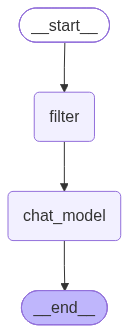

In [10]:
from langchain_core.messages import RemoveMessage

# Nodes
def filter_messages(state: MessagesState):
    # Delete all but the 2 most recent messages
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]
    return {"messages": delete_messages}

def chat_model_node(state: MessagesState):    
    return {"messages": [llm.invoke(state["messages"])]}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("filter", filter_messages)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "filter")
builder.add_edge("filter", "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
# Message list with a preamble
messages = [AIMessage("Hi.", name="Bot", id="1")]
messages.append(HumanMessage("Hi.", name="Ian", id="2"))
messages.append(AIMessage("So you said you were researching ocean mammals?", name="Bot", id="3"))
messages.append(HumanMessage("Yes, I know about whales. But what others should I learn about?", name="Lance", id="4"))

# Invoke
output = graph.invoke({'messages': messages})
for m in output['messages']:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Lance

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

In addition to whales, there are several other fascinating ocean mammals you might want to learn about: 

1. **Dolphins**: Highly intelligent and social creatures, dolphins are known for their playful behavior and complex communication skills. Some species include the bottlenose dolphin, common dolphin, and the orca, also known as the killer whale.

2. **Porpoises**: Similar to dolphins but generally smaller and with different facial structures and teeth, porpoises are less well-known but equally interesting.

3. **Seals**: These are pinnipeds with earless or true seals (like the harp seal) and eared seals (such 

## Filtering messages
Can filter the messages as we pass them to the chat model

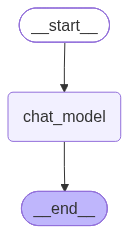

In [13]:
# Node
def chat_model_node(state: MessagesState):
    return {"messages": [llm.invoke(state["messages"][-1:])]}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [14]:
messages.append(output['messages'][-1])
messages.append(HumanMessage(f"Tell me more about Narwhals!", name="Ian"))

In [15]:
for m in messages:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

Hi.
================================ Human Message =================================
Name: Ian

Hi.
================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Lance

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

In addition to whales, there are several other fascinating ocean mammals you might want to learn about: 

1. **Dolphins**: Highly intelligent and social creatures, dolphins are known for their playful behavior and complex communication skills. Some species include the bottlenose dolphin, common dolphin, and the orca, also known as the killer whale.

2. **Porpoises**: Similar to dolphins but generally smaller and with differe

In [16]:
# Invoke, using message filtering
output = graph.invoke({'messages': messages})
for m in output['messages']:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

Hi.
================================ Human Message =================================
Name: Ian

Hi.
================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Lance

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

In addition to whales, there are several other fascinating ocean mammals you might want to learn about: 

1. **Dolphins**: Highly intelligent and social creatures, dolphins are known for their playful behavior and complex communication skills. Some species include the bottlenose dolphin, common dolphin, and the orca, also known as the killer whale.

2. **Porpoises**: Similar to dolphins but generally smaller and with differe

## Trim messages
Another approach to restrict messages history based upon a set number of tokens

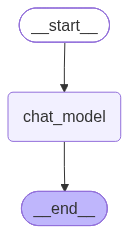

In [17]:
from langchain_core.messages import trim_messages

# Node
def chat_model_node(state: MessagesState):
    messages = trim_messages(
            state["messages"],
            max_tokens=100,
            strategy="last",
            token_counter=ChatOpenAI(model="gpt-4o"),
            allow_partial=False,
        )
    return {"messages": [llm.invoke(messages)]}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [18]:
messages.append(output['messages'][-1])
messages.append(HumanMessage(f"Tell me where Orcas live!", name="Ian"))

In [19]:
# Example of trimming messages
trim_messages(
            messages,
            max_tokens=100,
            strategy="last",
            token_counter=ChatOpenAI(model="gpt-4o"),
            allow_partial=False
        )

[HumanMessage(content='Tell me where Orcas live!', additional_kwargs={}, response_metadata={}, name='Ian')]

In [20]:
# Invoke, using message trimming in the chat_model_node 
messages_out_trim = graph.invoke({'messages': messages})